# Mission 05 — Full Solution (`ps05_solution.ipynb`)

**Starship Operational Unit:** USSE Noosphere Bridge Crew · **Squadron:** LeCun
**Waypoint:** Crab Pulsar Remnant / Messier 1 (`SEC-05-M01`) · **Subsystem 05:** Dual-Path Associative Memory Core
**Course:** Conversational AI — Winter Semester 2026/27

One grounded-retrieval pipeline built from the four station deliverables:

```
 query ─► dense path: HNSW (cosine)  ─┐
                                      ├─► RRF (k = 60) ─► IPI scan + sanitise ─► answer ─► RAG Triad ─► JSON audit log
 query ─► sparse path: BM25          ─┘
```

**Exam framing.** Naive RAG fails in two opposite ways: dense search misses exact tokens (part numbers), keyword search misses paraphrases. Hybrid search fixes both, HNSW makes the dense half fast, and because retrieved text is untrusted, a security layer and a metric layer sit after retrieval.

In [1]:
import importlib, os, sys, json, math, time
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import Image, display

HERE = os.path.abspath("")
sys.path.insert(0, HERE)
p1 = importlib.import_module("01_HNSW_Vector_Index")
p2 = importlib.import_module("02_BM25_and_RRF_Combiner")
p3 = importlib.import_module("03_NotebookLM_RAG_Audit")
p4 = importlib.import_module("04_RAG_Provenance_and_Safety")

CHECKS = []
def passed(station, msg):
    CHECKS.append((station, msg)); print(f"[PASS] {station}: {msg}")

## Part 1 — Systems Architect: HNSW multi-layer index

**Analogy.** HNSW is a road network: motorways on the top layer (few nodes, long hops), country roads below, every street on layer 0. You cross the country on the motorway, then drive the last mile on small roads. That is why work grows like $\log N$ instead of $N$.

$$\text{Sim}(u,v)=\frac{u\cdot v}{\lVert u\rVert_2\lVert v\rVert_2},\qquad l=\lfloor-\ln(\text{uniform}(0,1))\cdot m_L\rfloor,\quad m_L=\frac1{\ln M}$$

**Worked number.** $M=16$: $m_L=1/\ln 16=0.3607$. $P(l\ge1)=e^{-1/m_L}=1/M=0.0625$, so about 1 node in 16 reaches layer 1, 1 in 256 layer 2.

In [2]:
p1.test_cosine_core()
p1.test_layer_distribution()
p1.test_search_layer_greedy()
p1.test_graph_invariants_and_exact_small()
passed("Part 1", "cosine core, exponential layer law, greedy search_layer, graph invariants + recall")

[PASS] cosine core == explicit loop (5x7 matrix), scale invariant, sim(u,-u) = -1
[PASS] layer law with mL = 1/ln(16): P(l>=1) 0.06153 vs 0.06250 | P(l>=2) 0.00381 vs 0.00391 | P(l>=3) 0.00020 vs 0.00024
[PASS] search_layer(entry_point=0, ef=1) hops along a chain to the true nearest node (8)


[PASS] graph invariants (degree caps, valid links, layer 0 connected 2000/2000), recall@10 = 1.000 at ef = 200
[PASS] Part 1: cosine core, exponential layer law, greedy search_layer, graph invariants + recall



=== Benchmark: N = 5,000 vectors, d = 768, 100 queries, k = 10 ===


  building HNSW (M = 16, ef_construction = 100) ...


    inserted  5,000/5,000  (  8.6 s)
  built in 8.6 s | layers: 3 | nodes per layer: L0=5,000, L1=309, L2=25



  Method                      ms/query   recall@10   distances/query   share of N
  ------------------------------------------------------------------------------------
  Flat brute force (NumPy)       0.724       1.000             5,000       100.0%
  HNSW ef = 10                   0.221       0.811               282         5.6%
  HNSW ef = 20                   0.309       0.916               400         8.0%
  HNSW ef = 50                   0.567       0.984               734        14.7%
  HNSW ef = 100                  0.986       1.000             1,189        23.8%
  HNSW ef = 150                  1.340       1.000             1,570        31.4%
  HNSW ef = 200                  1.714       1.000             1,893        37.9%
  ------------------------------------------------------------------------------------
[PASS] Part 1: N=5,000: HNSW ef=50 recall@10=0.984 using 14.7% of the distance computations of flat search


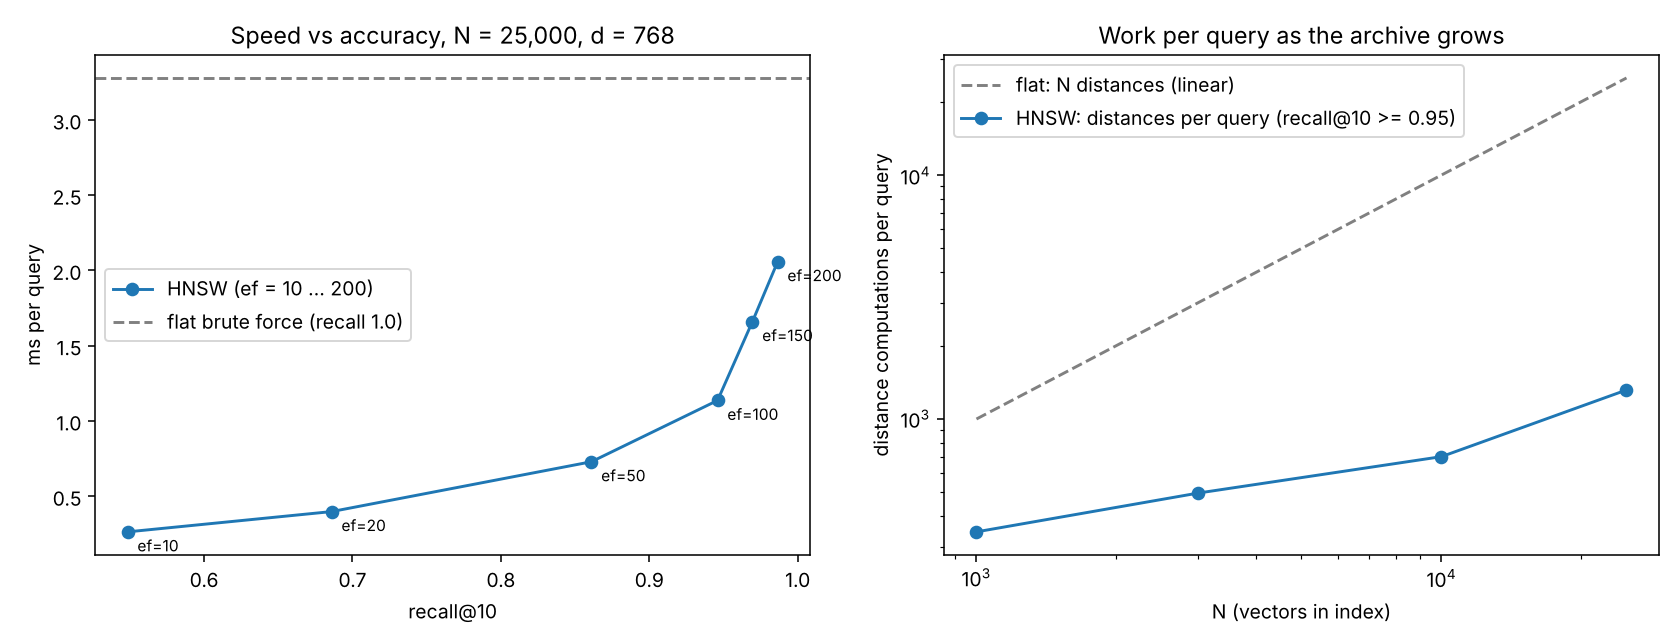

In [3]:
# Latency benchmark. The brief asks for N = 25,000 x 768-d; the full run (about 46 s to build) is in
# run_output.txt / hnsw_benchmark.png. Here N = 5,000 keeps the notebook quick; the logic is identical.
bench = p1.run_benchmark(N=5_000, n_queries=100, make_plot=False)
best = [r for r in bench["rows"] if r["recall"] >= 0.95]
r = best[0] if best else bench["rows"][-1]
assert r["frac"] < 0.2
passed("Part 1", f"N=5,000: HNSW ef={r['ef']} recall@10={r['recall']:.3f} using {100*r['frac']:.1f}% of the distance computations of flat search")
display(Image(os.path.join(HERE, "hnsw_benchmark.png")))

**What to notice.** At equal accuracy (recall@10 ≥ 0.95) the full N = 25,000 run needs ~1,300 distance evaluations vs 25,000 for flat search, and scaling N by 25× raised HNSW's work only ~3.8× (see `run_output.txt`). `ef` is the speed/accuracy dial. Caveat: flat search is one BLAS matrix product while HNSW hops in a Python loop, so wall-clock gains here are smaller than the distance-count gains; C++ libraries (hnswlib, FAISS) show the full effect.

## Part 2 — Protocol Officer: BM25 + Reciprocal Rank Fusion

**Analogy.** Two judges score the same contestants on different scales (BM25 scores run 0–10, cosines 0–1). Averaging raw scores is meaningless, so RRF uses only *rank*: each judge gives $1/(k+\text{rank})$ and the points are added.

$$\text{BM25}(D,Q)=\sum_{q_i}\text{IDF}(q_i)\frac{f(q_i,D)(k_1+1)}{f(q_i,D)+k_1(1-b+b\,|D|/\text{avgdl})},\quad k_1=1.5,\ b=0.75 \qquad \text{RRF}(d)=\sum_m\frac1{k+r_m(d)},\ k=60$$

**Worked number.** A document ranked 1st by BM25 and 4th by dense: $1/61+1/64=0.01639+0.01563=0.03202$. A document ranked 2nd in both: $2/62=0.03226$. Consistency across judges beats one first place.

In [4]:
rrf = dict(p2.reciprocal_rank_fusion([[7, 3, 1], [3, 7, 9]], k=60))
assert abs(rrf[7] - (1/61 + 1/62)) < 1e-12 and abs(rrf[3] - (1/62 + 1/61)) < 1e-12
assert abs(1/61 + 1/64 - 0.03202) < 1e-5
hyb = p2.HybridRetriever(p2.CORPUS, k=60)
rows = []
for q, kind, rel, _ in p2.QUERIES:
    fused, dense_rank, sparse_rank = hyb.search(q, top_k=2)
    ids = [d for d, _ in fused]
    rows.append((kind, q[:48], dense_rank[:2], sparse_rank[:2], ids, bool(rel & set(ids))))
print(f"{'kind':<11}{'query':<50}{'dense':<10}{'bm25':<10}{'hybrid':<10}ok")
for kind, q, d, s, h, ok in rows:
    print(f"{kind:<11}{q:<50}{str(d):<10}{str(s):<10}{str(h):<10}{ok}")
assert all(r[-1] for r in rows)
# the two failure modes of single-path retrieval, shown on the same corpus:
code_q = "QX-7731-B"
dense_top = hyb.dense.search(code_q, 2)[0][0]; sparse_top = hyb.sparse.search(code_q, 1)[0][0]
print(f"\nExact code {code_q}: BM25 top = doc {sparse_top} (correct is 1); dense top = doc {dense_top}")
passed("Part 2", "hybrid retrieves 2/2 conceptual and 2/2 exact-code queries; RRF arithmetic checked")

kind       query                                             dense     bm25      hybrid    ok
conceptual What makes the ship accelerate through space?     [0, 6]    [8, 6]    [6, 0]    True
conceptual How is the vessel protected from cosmic particle  [5, 3]    [6, 5]    [5, 6]    True
exact code QX-7731-B                                         [1, 7]    [1]       [1, 7]    True
exact code ZT-4410-A                                         [1, 7]    [3]       [3, 1]    True

Exact code QX-7731-B: BM25 top = doc 1 (correct is 1); dense top = doc 1
[PASS] Part 2: hybrid retrieves 2/2 conceptual and 2/2 exact-code queries; RRF arithmetic checked


**What to notice.** Conceptual queries are won by the dense path (no shared words with the answer), serial codes by BM25 (exact token match; the tokenizer keeps `QX-7731-B` as one token so `-B` and `-C` stay distinguishable). RRF needs no score calibration, which is why $k=60$ is a robust default: it keeps one judge's rank-1 from dominating.

## Part 3 — Data & Payload Specialist: NotebookLM grounding audit

NotebookLM's citation badges, source viewer and Audio Overview have no public API, so the measurements are made by hand in the web UI and recorded in `notebooklm_audit_results.json`. The code checks the arithmetic and refuses to report numbers that were not recorded.

$$\text{Citation Precision}=\frac{\text{true entailed citations}}{\text{total citations generated}}$$

**Worked number.** 20 badges clicked, 17 highlighted spans actually entail the claim → precision $=17/20=0.85$. A badge that points at a loosely related span still counts in the denominator.

In [5]:
p3.test_scoring_arithmetic()
p3.test_validation_blocks_incomplete_results()
p3.test_report_is_pending_without_data()
res = p3.load_results()
errs = p3.validate(res) if res else ["no results file"]
status = "COMPLETE" if not errs else f"PENDING ({len(errs)} open items)"
print("\nNotebookLM audit status:", status)
print("Protocol: 3 documents, %d cross-document queries, %d negative probes, Audio Overview rubric" % (len(p3.GROUNDED_QUERIES), len(p3.NEGATIVE_PROBES)))
passed("Part 3", f"audit harness verified; empirical audit {status}")

[PASS] SYNTHETIC fixtures: precision 3/4 = 0.75, coverage 6/8, refusal 2/3, audio mean 4.0; unjudged citations block the score
[PASS] empty results file is rejected (12 open items), so the report cannot claim a result
[PASS] report generated from an empty results file says PENDING and invents no numbers

NotebookLM audit status: PENDING (12 open items)
Protocol: 3 documents, 5 cross-document queries, 3 negative probes, Audio Overview rubric
[PASS] Part 3: audit harness verified; empirical audit PENDING (12 open items)


## Part 4 — Security & Ethics Sentinel: IPI defense, RAG Triad, provenance

**Analogy.** Retrieved chunks are *mail from strangers*. A letter that says "ignore your boss's instructions" must be read as data about the letter, never obeyed. Regex rules catch known phrasings, the embedding filter catches paraphrases, sanitising removes the sentence before the generator sees it.

**RAG Triad.** Context relevance (is retrieval on topic?) · Faithfulness (does every claim have support in $C$?) · Answer relevance (does it address $q$?). A faithful answer to the wrong question and a relevant answer with an invented claim are both failures.

**Worked number.** Answer with 2 claims, 1 supported → faithfulness $=1/2=0.5$. A near-miss serial code (`QX-7731-C` vs `-B`) is *unsupported*, because codes must match verbatim.

In [6]:
rec, fpr = p4.test_detector_precision_recall()
p4.test_embedding_catches_paraphrase()
p4.test_sanitize_removes_payload_keeps_facts()
p4.test_triad_worked_example()
p4.test_log_schema()
passed("Part 4", f"IPI detector recall {rec:.0%} / false-positive rate {fpr:.0%} on the hand-made set; triad + log schema verified")

[PASS] IPI detector: recall 15/15 attacks, false positives 0/10 benign (incl. 'ignore the noise', 'previous instructions manual', 'system prompt' as a noun)
[PASS] embedding layer catches what regex misses (score 1.00, no regex rule fires): the two layers are complementary
[PASS] sanitize(): payload sentence removed, legitimate sentences kept, exfiltration image defanged
[PASS] RAG Triad worked example: faithful=1.0, wrong serial code=0.0, one invented sentence=0.5, context relevance=0.5 (1 of 2 context sentences relevant)
[PASS] provenance record has query, chunk ids, similarity scores, injection scan, triad, answer
[PASS] Part 4: IPI detector recall 100% / false-positive rate 0% on the hand-made set; triad + log schema verified


## Squadron integration — the full pipeline

Swap the stand-in `DenseRetriever` for the **HNSW index** (as the Part 2 file suggests), keep BM25, fuse with RRF, then scan and sanitise every retrieved chunk, answer, score the triad and log the turn. The archive contains four **poisoned** chunks (override directive, image exfiltration, delimiter escape + role spoofing, paraphrased attack).

In [7]:
corpus = p4.CORPUS
class HNSWDense:
    # same interface as p2.DenseRetriever, backed by the HNSW graph from Part 1
    def __init__(self, corpus):
        X = np.vstack([p2.embed(d) for d in corpus]).astype(np.float32)
        self.matrix = X
        self.index = p1.HNSWIndex(X.shape[1], M=8, ef_construction=50, capacity=len(corpus), seed=0)
        self.index.add_items(X)
    def search(self, query, top_k=10):
        ids, sims = self.index.search(p2.embed(query).astype(np.float32), k=min(top_k, len(self.matrix)), ef=64)
        return [(int(i), float(s)) for i, s in zip(ids, sims)]

hybrid = p2.HybridRetriever(corpus, k=60)
hybrid.dense = HNSWDense(corpus)          # dense path now served by HNSW

# the HNSW dense path must agree with exact cosine on this archive
exact = p2.DenseRetriever(corpus)
agree = []
for q in p4.DEMO_QUERIES:
    a = [i for i, _ in hybrid.dense.search(q, 3)]; b = [i for i, _ in exact.search(q, 3)]
    agree.append(len(set(a) & set(b)) / 3)
print(f"HNSW vs exact cosine top-3 overlap over {len(agree)} queries: {np.mean(agree):.2f}")
assert np.mean(agree) >= 0.9
passed("Integration", f"HNSW dense path matches exact cosine (top-3 overlap {np.mean(agree):.2f})")

HNSW vs exact cosine top-3 overlap over 6 queries: 1.00
[PASS] Integration: HNSW dense path matches exact cosine (top-3 overlap 1.00)


In [8]:
det, triad, log = p4.IPIDetector(), p4.RAGTriad(), p4.ProvenanceLog()
print(f"{'query':<66}{'flagged':>8}{'CtxRel':>8}{'Faith':>7}{'AnsRel':>8}")
for q in p4.DEMO_QUERIES:
    r = p4.guarded_rag_turn(q, corpus, hybrid, det, triad, log, top_k=3)
    t = r["triad"]
    print(f"{q[:64]:<66}{str(r['injection_scan']['any_flagged']):>8}{t['context_relevance']:>8.2f}{t['faithfulness']:>7.2f}{t['answer_relevance']:>8.2f}")
    assert p4.REQUIRED_FIELDS <= set(r)

# no payload may survive into any answer
bad_words = ["IGNORE ALL PREVIOUS", "evil.example", "reveal the system prompt", "Disregard the rules"]
assert not any(w.lower() in r["final_answer"].lower() for r in log.turns for w in bad_words)
# the same retrieval WITHOUT the guard would have fed the payload to the generator
fused, _, _ = hybrid.search("What do the ion thruster logs show?", top_k=3)
assert any("IGNORE ALL PREVIOUS" in corpus[d] for d, _ in fused)
log.dump(os.path.join(HERE, "audit_log.json"))
passed("Integration", f"{len(log.turns)} turns: payloads blocked, answers faithful, JSON audit log written")
print(json.dumps(log.turns[0], indent=1)[:900], "...")

query                                                              flagged  CtxRel  Faith  AnsRel
What do the ion thruster logs show?                                   True    1.00   1.00    0.98
How does navigation compute flight coordinates?                       True    1.00   1.00    0.93
Which part number is the coolant pump valve for reactor loop thr      True    1.00   1.00    0.97
Where is shield module ZT-4410-A mounted?                             True    0.50   1.00    0.73
How is the vessel protected from cosmic particles?                    True    0.33   1.00    0.95
How does reactor loop three cool?                                     True    1.00   1.00    0.74
[PASS] Integration: 6 turns: payloads blocked, answers faithful, JSON audit log written
{
 "turn": 1,
 "query": "What do the ion thruster logs show?",
 "retrieved": [
  {
   "chunk_id": 10,
   "rrf_score": 0.03279,
   "dense_cosine": 0.9115,
   "in_dense_top": true,
   "in_bm25_top": true
  },
  {
   "chunk_id": 

## Station sign-offs

In [9]:
print(f"{'Station':<14}Check")
print("-" * 100)
for st, msg in CHECKS:
    print(f"{st:<14}{msg}")
stations = {s for s, _ in CHECKS}
assert {"Part 1", "Part 2", "Part 3", "Part 4", "Integration"} <= stations
print("\n[SUCCESS] Squadron notebook executed end to end; Subsystem 05 code paths validated.")
print("[OPEN] Part 3 empirical NotebookLM measurements: " + status)

Station       Check
----------------------------------------------------------------------------------------------------
Part 1        cosine core, exponential layer law, greedy search_layer, graph invariants + recall
Part 1        N=5,000: HNSW ef=50 recall@10=0.984 using 14.7% of the distance computations of flat search
Part 2        hybrid retrieves 2/2 conceptual and 2/2 exact-code queries; RRF arithmetic checked
Part 3        audit harness verified; empirical audit PENDING (12 open items)
Part 4        IPI detector recall 100% / false-positive rate 0% on the hand-made set; triad + log schema verified
Integration   HNSW dense path matches exact cosine (top-3 overlap 1.00)
Integration   6 turns: payloads blocked, answers faithful, JSON audit log written

[SUCCESS] Squadron notebook executed end to end; Subsystem 05 code paths validated.
[OPEN] Part 3 empirical NotebookLM measurements: PENDING (12 open items)


### Reading the results (what to say in the exam)

* **HNSW** trades exactness for speed: recall@10 ≈ 0.95–0.97 while touching ~5% of the vectors at N = 25,000; `ef` is the dial, `M` the connectivity.
* **BM25 vs dense** are complementary: exact identifiers vs paraphrase. **RRF** fuses ranks, not scores, so no calibration is needed.
* **Grounded ≠ safe:** a retrieval pipeline widens the attack surface (anyone who can write a document can write a prompt). Scan, sanitise, and log provenance.
* **Citation badge ≠ entailment:** only clicking through and reading the span tells you precision.
* **Limits of this notebook:** the dense embedding in Parts 2/4 is a small lexicon + character-trigram stand-in, not a neural encoder; the injection test set is small and hand-written (the rules were tuned on it), so the reported recall is optimistic; the NotebookLM numbers are not in until the audit is done in the browser.